In [1]:
import torch
import os
import platform

print("Python Version:", platform.python_version())
print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

Python Version: 3.13.18
PyTorch Version: 2.14.1+cpu
CUDA Available: False
Running on CPU


In [2]:
!pip install -q onnx onnxruntime matplotlib torchvision

In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import numpy as np
import os
import onnx
import onnxruntime as ort

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
os.makedirs("/content/artifacts", exist_ok=True)
os.makedirs("/content/results", exist_ok=True)

print("Project directories created!")
print(os.listdir("/content"))

Project directories created!
['.config', 'artifacts', 'results', 'sample_data']


In [10]:
import torch
import torchvision
import torchvision.transforms as transforms

# Image transformation
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

# Load training dataset
train_dataset = torchvision.datasets.MNIST(
    root="/content/data",
    train=True,
    download=True,
    transform=transform
)

# Load testing dataset
test_dataset = torchvision.datasets.MNIST(
    root="/content/data",
    train=False,
    download=True,
    transform=transform
)

# Create DataLoaders
train_loader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("MNIST Dataset Loaded Successfully!")
print("Training Images:", len(train_dataset))
print("Testing Images:", len(test_dataset))
print("Training Batches:", len(train_loader))
print("Testing Batches:", len(test_loader))

100%|██████████| 9.91M/9.91M [00:00<00:00, 16.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 401kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.79MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.78MB/s]

MNIST Dataset Loaded Successfully!
Training Images: 60000
Testing Images: 10000
Training Batches: 938
Testing Batches: 157


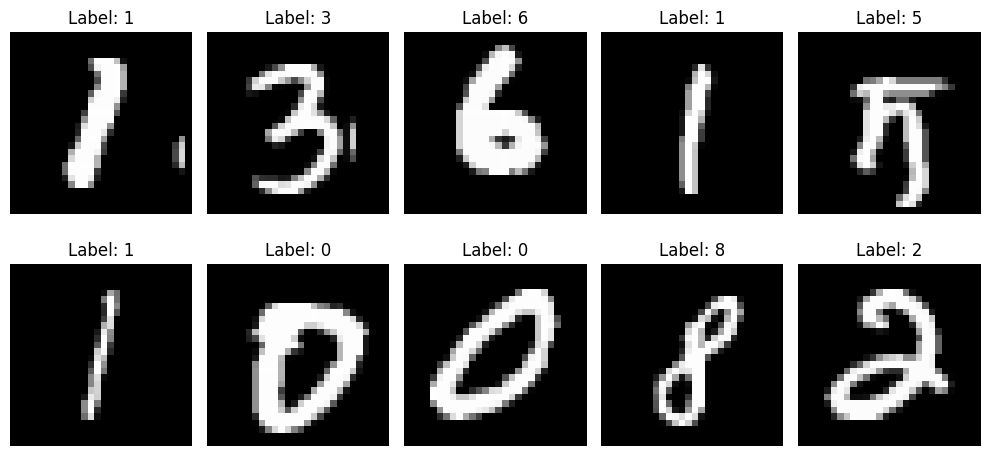

In [6]:
images, labels = next(iter(train_loader))

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i].squeeze(), cmap="gray")
    plt.title(f"Label: {labels[i].item()}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [2]:
import torch
import torch.nn as nn

class CNNModel(nn.Module):

    def __init__(self):
        super(CNNModel, self).__init__()

        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2, 2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):

        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))

        x = x.view(x.size(0), -1)

        x = self.relu3(self.fc1(x))
        x = self.fc2(x)

        return x


model = CNNModel()

print("CNN Model Architecture Created Successfully!")
print(model)

CNN Model Architecture Created Successfully!
CNNModel(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (relu3): ReLU()
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [3]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("Selected Device:", device)
print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

print("Model successfully moved to:", device)

Selected Device: cuda
GPU Available: True
GPU Name: Tesla T4
Model successfully moved to: cuda


In [6]:
import torch
import torch.nn as nn
import torch.optim as optim

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Loss Function:", criterion)
print("Optimizer:", optimizer)
print("Cell 9 Executed Successfully!")

Loss Function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Cell 9 Executed Successfully!


In [11]:
import torch

epochs = 2

for epoch in range(epochs):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    print(f"Epoch [{epoch+1}/{epochs}] Loss: {average_loss:.4f}")

print("Model Training Completed Successfully!")

Epoch [1/2] Loss: 0.1320
Epoch [2/2] Loss: 0.0439
Model Training Completed Successfully!


In [12]:
import torch

model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predicted = outputs.argmax(dim=1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print("Total Images:", total)
print("Correct Predictions:", correct)
print("Model Accuracy: {:.2f}%".format(accuracy))

Total Images: 10000
Correct Predictions: 9873
Model Accuracy: 98.73%


In [13]:
import os
import torch

os.makedirs("/content/artifacts", exist_ok=True)

checkpoint_path = "/content/artifacts/model_checkpoint.pth"

torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "epochs": epochs,
    "accuracy": accuracy
}, checkpoint_path)

print("Checkpoint Saved Successfully!")
print("Location:", checkpoint_path)

Checkpoint Saved Successfully!
Location: /content/artifacts/model_checkpoint.pth


In [14]:
import torch

checkpoint = torch.load(
    "/content/artifacts/model_checkpoint.pth",
    map_location=device,
    weights_only=True
)

loaded_model = CNNModel().to(device)

loaded_model.load_state_dict(
    checkpoint["model_state_dict"]
)

loaded_model.eval()

print("Checkpoint Loaded Successfully!")
print("Training Epochs:", checkpoint["epochs"])
print("Saved Accuracy:", checkpoint["accuracy"])

Checkpoint Loaded Successfully!
Training Epochs: 2
Saved Accuracy: 98.73


In [15]:
import torch

dummy_input = torch.randn(1, 1, 28, 28).to(device)

model.eval()
loaded_model.eval()

with torch.no_grad():

    original_output = model(dummy_input)
    loaded_output = loaded_model(dummy_input)

difference = torch.max(
    torch.abs(original_output - loaded_output)
).item()

print("Maximum Difference:", difference)

if difference < 1e-6:
    print("Checkpoint Verification Successful!")
else:
    print("Checkpoint Verification Failed!")

Maximum Difference: 0.0
Checkpoint Verification Successful!


In [17]:
!pip install -q onnx
import torch
import os

onnx_path = "/content/artifacts/model.onnx"

loaded_model = loaded_model.cpu()
loaded_model.eval()

dummy_input = torch.randn(1, 1, 28, 28)

torch.onnx.export(
    loaded_model,
    dummy_input,
    onnx_path,
    export_params=True,
    opset_version=17,
    do_constant_folding=True,
    input_names=["input"],
    output_names=["output"],
    dynamo=False
)

print("ONNX Model Exported Successfully!")
print("Saved Location:", onnx_path)

ONNX Model Exported Successfully!
Saved Location: /content/artifacts/model.onnx


/tmp/ipykernel_765/1193861280.py:12: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


In [18]:
import onnx
import os

onnx_path = "/content/artifacts/model.onnx"

onnx_model = onnx.load(onnx_path)

onnx.checker.check_model(onnx_model)

print("ONNX Graph Validation Successful!")

print("\nModel Inputs:")

for item in onnx_model.graph.input:
    print(item.name)

print("\nModel Outputs:")

for item in onnx_model.graph.output:
    print(item.name)

print("\nONNX File Size:",
      round(os.path.getsize(onnx_path) / 1024, 2), "KB")

ONNX Graph Validation Successful!

Model Inputs:
input

Model Outputs:
output

ONNX File Size: 1648.62 KB


In [20]:
!pip install -q onnxruntime
import onnxruntime as ort
import numpy as np

onnx_path = "/content/artifacts/model.onnx"

session = ort.InferenceSession(
    onnx_path,
    providers=["CPUExecutionProvider"]
)

test_input = np.random.randn(
    1, 1, 28, 28
).astype(np.float32)

onnx_output = session.run(
    ["output"],
    {"input": test_input}
)

print("ONNX Inference Successful!")
print("Input Shape:", test_input.shape)
print("Output Shape:", onnx_output[0].shape)
print("Predicted Class:", np.argmax(onnx_output[0]))

ONNX Inference Successful!
Input Shape: (1, 1, 28, 28)
Output Shape: (1, 10)
Predicted Class: 2


In [21]:
import torch
import numpy as np

loaded_model.eval()

test_input = np.random.randn(
    1, 1, 28, 28
).astype(np.float32)

with torch.no_grad():

    pytorch_output = loaded_model(
        torch.from_numpy(test_input)
    ).numpy()

onnx_output = session.run(
    ["output"],
    {"input": test_input}
)[0]

difference = np.max(
    np.abs(pytorch_output - onnx_output)
)

print("PyTorch Prediction:", np.argmax(pytorch_output))
print("ONNX Prediction:", np.argmax(onnx_output))
print("Maximum Difference:", difference)

if difference < 1e-4:
    print("Both Models Produce Matching Outputs!")
else:
    print("Output Difference Detected!")

PyTorch Prediction: 5
ONNX Prediction: 5
Maximum Difference: 3.1292439e-07
Both Models Produce Matching Outputs!


In [22]:
!nvidia-smi

Thu Nov 26 03:44:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   62C    P0             29W /   70W |     231MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [23]:
%pip install -q tensorrt-cu12

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [24]:
import tensorrt as trt

print("TensorRT Version:", trt.__version__)
print("TensorRT Imported Successfully!")

assert torch.cuda.is_available(), "CUDA GPU is not available"

print("GPU:", torch.cuda.get_device_name(0))

TensorRT Version: 11.5.0.63
TensorRT Imported Successfully!
GPU: Tesla T4


In [26]:
import tensorrt as trt
import os

onnx_path = "/content/artifacts/model.onnx"
engine_path = "/content/artifacts/model.engine"

logger = trt.Logger(trt.Logger.WARNING)

builder = trt.Builder(logger)

# In modern TensorRT versions (10+), we specify explicit batch using integer flag 1 << 0
network = builder.create_network(1 << 0)

parser = trt.OnnxParser(network, logger)

with open(onnx_path, "rb") as f:
    onnx_data = f.read()

if not parser.parse(onnx_data):

    print("ONNX Parsing Failed!")

    for i in range(parser.num_errors):
        print(parser.get_error(i))

    raise RuntimeError("ONNX parsing failed")

config = builder.create_builder_config()

config.set_memory_pool_limit(
    trt.MemoryPoolType.WORKSPACE,
    1 << 30
)

serialized_engine = builder.build_serialized_network(
    network,
    config
)

if serialized_engine is None:
    raise RuntimeError("TensorRT Engine Generation Failed!")

with open(engine_path, "wb") as f:
    f.write(serialized_engine)

print("TensorRT Engine Created Successfully!")
print("Engine Location:", engine_path)
print("Engine Size:",
      round(os.path.getsize(engine_path) / 1024, 2), "KB")

TensorRT Engine Created Successfully!
Engine Location: /content/artifacts/model.engine
Engine Size: 1720.75 KB


In [27]:
import tensorrt as trt

logger = trt.Logger(trt.Logger.WARNING)

runtime = trt.Runtime(logger)

engine_path = "/content/artifacts/model.engine"

with open(engine_path, "rb") as f:
    engine_data = f.read()

engine = runtime.deserialize_cuda_engine(engine_data)

if engine is None:
    raise RuntimeError("TensorRT Engine Loading Failed!")

print("TensorRT Engine Loaded Successfully!")

print("\nEngine Tensor Details:")

for i in range(engine.num_io_tensors):

    name = engine.get_tensor_name(i)

    print("Tensor:", name)
    print("Shape:", engine.get_tensor_shape(name))
    print("Mode:", engine.get_tensor_mode(name))

TensorRT Engine Loaded Successfully!

Engine Tensor Details:
Tensor: input
Shape: (1, 1, 28, 28)
Mode: TensorIOMode.INPUT
Tensor: output
Shape: (1, 10)
Mode: TensorIOMode.OUTPUT


In [28]:
import os

artifact_dir = "/content/artifacts"

files_list = [
    "model_checkpoint.pth",
    "model.onnx",
    "model.engine"
]

print("====================================")
print("       MODEL ARTEFACT REPORT")
print("====================================")

for filename in files_list:

    filepath = os.path.join(artifact_dir, filename)

    if os.path.exists(filepath):

        size = os.path.getsize(filepath) / 1024

        print("\nFile:", filename)
        print("Status: SUCCESS")
        print("Size:", round(size, 2), "KB")

    else:

        print("\nFile:", filename)
        print("Status: NOT GENERATED")

print("\n====================================")
print("       REPORT COMPLETED")
print("====================================")

       MODEL ARTEFACT REPORT

File: model_checkpoint.pth
Status: SUCCESS
Size: 4951.46 KB

File: model.onnx
Status: SUCCESS
Size: 1648.62 KB

File: model.engine
Status: SUCCESS
Size: 1720.75 KB

       REPORT COMPLETED
